1. Dataset Selection and Reading

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("spotify.csv")

#view first 5 rows
print(df.head())


                 track_id                                         track_name  \
0  6f807x0ima9a1j3VPbc7VN  I Don't Care (with Justin Bieber) - Loud Luxur...   
1  0r7CVbZTWZgbTCYdfa2P31                    Memories - Dillon Francis Remix   
2  1z1Hg7Vb0AhHDiEmnDE79l                    All the Time - Don Diablo Remix   
3  75FpbthrwQmzHlBJLuGdC7                  Call You Mine - Keanu Silva Remix   
4  1e8PAfcKUYoKkxPhrHqw4x            Someone You Loved - Future Humans Remix   

       track_artist  track_popularity          track_album_id  \
0        Ed Sheeran                66  2oCs0DGTsRO98Gh5ZSl2Cx   
1          Maroon 5                67  63rPSO264uRjW1X5E6cWv6   
2      Zara Larsson                70  1HoSmj2eLcsrR0vE9gThr4   
3  The Chainsmokers                60  1nqYsOef1yKKuGOVchbsk6   
4     Lewis Capaldi                69  7m7vv9wlQ4i0LFuJiE2zsQ   

                                    track_album_name track_album_release_date  \
0  I Don't Care (with Justin Bieber) [Loud Luxu

2. Data Understanding

In [3]:
# Shape of dataset
print("Rows, Columns:", df.shape)

# Column info
print(df.info())

# Summary statistics
print(df.describe())

# Check for null values
print(df.isnull().sum())


Rows, Columns: (32833, 23)
<class 'pandas.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  str    
 1   track_name                32828 non-null  str    
 2   track_artist              32828 non-null  str    
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  str    
 5   track_album_name          32828 non-null  str    
 6   track_album_release_date  32833 non-null  str    
 7   playlist_name             32833 non-null  str    
 8   playlist_id               32833 non-null  str    
 9   playlist_genre            32833 non-null  str    
 10  playlist_subgenre         32833 non-null  str    
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int

3. Data Transformation

In [4]:
# Change data type
df['loudness'] = pd.to_datetime(df['loudness'])

# Drop unnecessary columns
df = df.drop(['speechiness'], axis=1)

# Add new column (e.g., song length in minutes)
df['duration_min'] = df['duration_ms'] / 60000


4. Handling Null Values (Mean Imputation

In [5]:
# Fill numeric nulls with mean
for col in df.select_dtypes(include=['float64', 'int64']).columns:
    df[col + '_mean'] = df[col].fillna(df[col].mean())

5. Insight Generation

In [6]:
# Top 10 most popular songs
top_songs = df.nlargest(10, 'track_popularity')[['track_name', 'track_popularity']]
print("Top 10 Songs by Popularity:\n", top_songs)

# Average popularity by year
df['track_album_release_date'] = pd.to_datetime(
    df['track_album_release_date'], errors='coerce'
)
df['year'] = df['track_album_release_date'].dt.year
avg_popularity = df.groupby('year')['track_popularity'].mean()
print("Average Popularity by Year:\n", avg_popularity)

# Correlation between danceability and energy
correlation = df['danceability'].corr(df['energy'])
print("Correlation between Danceability and Energy:", correlation)


Top 10 Songs by Popularity:
             track_name  track_popularity
1551      Dance Monkey               100
20091     Dance Monkey               100
20092          ROXANNE                99
21468          ROXANNE                99
23104          ROXANNE                99
30202          ROXANNE                99
687               Tusa                98
711           Memories                98
716    Blinding Lights                98
1300          Memories                98
Average Popularity by Year:
 year
1957.0    59.000000
1958.0    73.000000
1961.0    47.000000
1963.0    36.250000
1964.0    42.750000
            ...    
2016.0    38.479659
2017.0    41.788541
2018.0    45.878623
2019.0    51.408415
2020.0    46.461146
Name: track_popularity, Length: 61, dtype: float64
Correlation between Danceability and Energy: -0.08607315593777046


6. Data Visualization

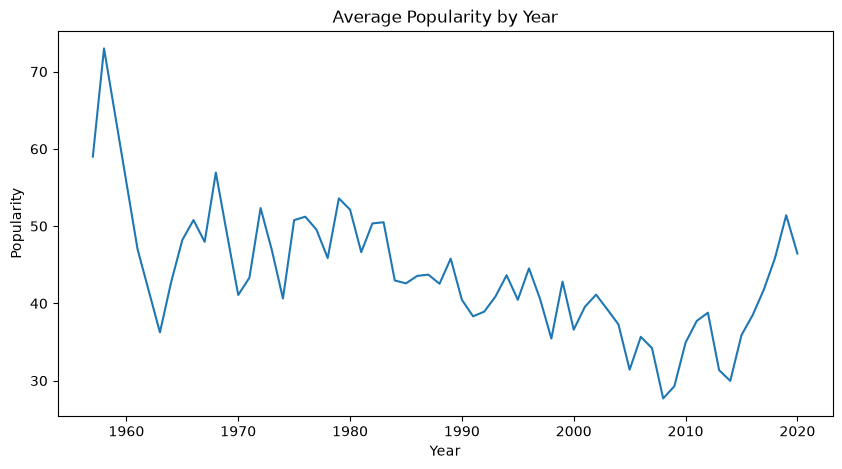

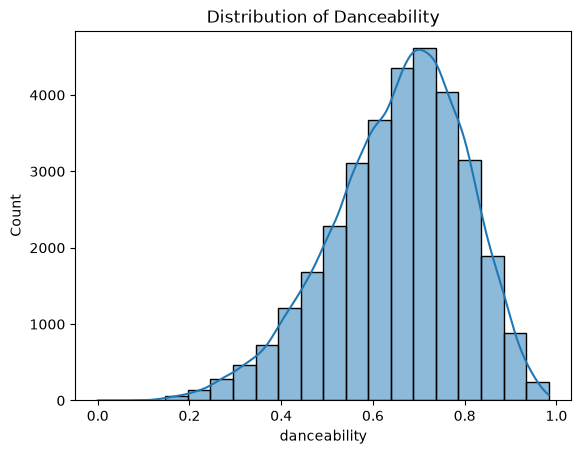

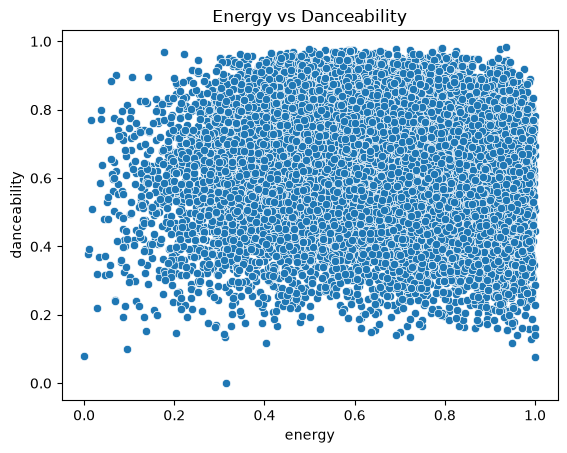

In [7]:
# Popularity trend over years
plt.figure(figsize=(10,5))
sns.lineplot(x=avg_popularity.index, y=avg_popularity.values)
plt.title("Average Popularity by Year")
plt.xlabel("Year")
plt.ylabel("Popularity")
plt.show()

# Distribution of danceability
sns.histplot(df['danceability'], bins=20, kde=True)
plt.title("Distribution of Danceability")
plt.show()

# Scatter plot: Energy vs Danceability
sns.scatterplot(x='energy', y='danceability', data=df)
plt.title("Energy vs Danceability")
plt.show()